# Aşama 13: Enerjili, sezonlu gökyüzü taraması

Aşama 7'deki tarafsız taramayı, Aşama 12'nin daha doğru modeliyle tekrarlıyoruz: her noktada **yön + enerji**, **sezonlar ayrı**, **γ serbest**. Bu, IceCube'un yayımladığı tüm gökyüzü taramasına en çok yaklaştığımız hâl.

Beklentimiz: en sıcak nokta yine NGC 1068 civarında, ama γ'yı da serbest bıraktığımız için "başka yere bakma" düzeltmesi büyüyecek (daha çok bilet).

In [1]:
import sys; sys.path.append('../src')
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import icecube_ps as ps
importlib.reload(ps)
assert float(ps.SURUM) >= float('13.1'), f"src/icecube_ps.py eski sürüm ({getattr(ps, 'SURUM', 'yok')}). Yenisini kopyala, kernel'i yeniden başlat."
try:
    from tqdm.auto import tqdm          # ilerleme çubuğu
except ImportError:
    tqdm = None

pd.set_option('display.float_format', '{:.3g}'.format)
DATA, RESULTS = Path('../data'), Path('../results')
ev = ps.veri_yukle(DATA)
B = ps.ArkaPlan(ev['dec'].values)
print('icecube_ps', ps.SURUM, '| olay:', f'{len(ev):,}')
import os, time
from scipy import stats
N_CEKIRDEK = os.cpu_count()

icecube_ps 15.0 | olay: 1,134,450


c:\Users\musab\Desktop\Projects\Claude_Notrino_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
M = ps.SezonluModel(ev, ps.etkin_alanlari_yukle(DATA), ps.canli_sureler_yukle(DATA), ps.smearingleri_yukle(DATA))
T = ps.SezonluTarayici(M)
ra_g, dec_g = ps.gok_izgarasi(0.7)
print(f'{len(ra_g):,} nokta,  γ ızgarası: {T.gamma}')

45,859 nokta,  γ ızgarası: [1.5 1.8 2.1 2.4 2.7 3.  3.3 3.6 3.9 4.2 4.5]


## 1. Gerçek gökyüzü

⏱️ Birkaç dakika (tek çekirdek).

In [3]:
dosya = RESULTS / 'asama13_harita.npz'
if dosya.exists():
    h = np.load(dosya); ns_g, g_g, ts_g = h['ns'], h['gamma'], h['ts']
else:
    ns_g, g_g, ts_g = T.harita(ra_g, dec_g, ilerleme=tqdm)
    np.savez(dosya, ra=ra_g, dec=dec_g, ns=ns_g, gamma=g_g, ts=ts_g)
print(f'En büyük TS = {ts_g.max():.1f}')

En büyük TS = 21.8


## 2. Karıştırılmış gökyüzleri (paralel)

Hem yerel p-değerini kalibre etmek hem de "başka yere bakma" düzeltmesi için. γ serbest olduğu için TS artık tam χ²(1) değil; dağılımı karıştırılmış haritalardan ölçüyoruz.

⏱️ 100 harita, tüm çekirdeklerle muhtemelen 15–30 dakika. Parça parça kaydediliyor, durdurup devam edebilirsin.

In [4]:
HEDEF = 100
dosya_max = RESULTS / 'asama13_karisik_max_ts_v2.npy'      # v2: ince taramalı
dosya_ornek = RESULTS / 'asama13_karisik_ornek_v2.npy'
max_ts = list(np.load(dosya_max)) if dosya_max.exists() else []
ornek = list(np.load(dosya_ornek)) if dosya_ornek.exists() else []
parti = 2 * N_CEKIRDEK
while len(max_ts) < HEDEF:
    n_yeni = min(parti, HEDEF - len(max_ts))
    arg = [(0.7, 130_000 + len(max_ts) + i) for i in range(n_yeni)]
    t = time.perf_counter()
    for mx, ts_harita in ps.paralel_sezonlu(arg, N_CEKIRDEK, DATA.resolve()):
        max_ts.append(mx)
        if len(ornek) < 5:
            ornek.append(ts_harita)                  # kalibrasyon için birkaç tam harita
    np.save(dosya_max, np.array(max_ts)); np.save(dosya_ornek, np.array(ornek))
    print(f'{len(max_ts)}/{HEDEF}  ({(time.perf_counter() - t) / n_yeni:.0f} s/harita)', flush=True)
max_ts, ornek = np.array(max_ts), np.array(ornek)

Kalibrasyon: TS>0 oranı η = 0.51, etkin serbestlik derecesi = 1.00


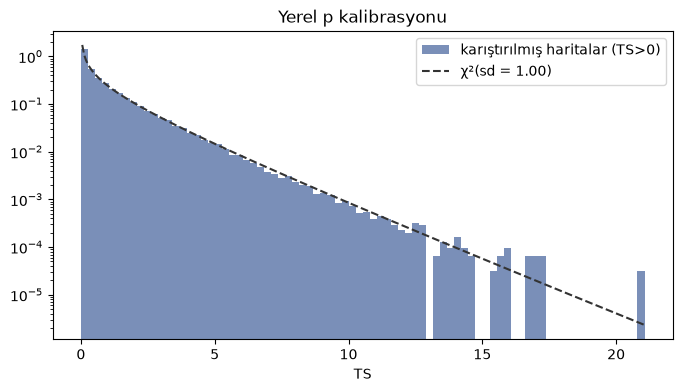

In [5]:
# Yerel p-değeri: karıştırılmış haritaların nokta TS'lerinden η·χ²(sd) uydur
havuz = ornek.ravel()
eta, sd = np.mean(havuz > 0), np.mean(havuz[havuz > 0])
yerel_p = lambda ts: np.where(ts > 0, eta * stats.chi2.sf(ts, df=sd), 1.0)
print(f'Kalibrasyon: TS>0 oranı η = {eta:.2f}, etkin serbestlik derecesi = {sd:.2f}')

fig, ax = plt.subplots(figsize=(8, 4))
x = np.linspace(0.05, max(15, havuz.max()), 300)
ax.hist(havuz[havuz > 0], bins=80, density=True, color='#7a8fb8', label='karıştırılmış haritalar (TS>0)')
ax.plot(x, stats.chi2.pdf(x, df=sd), color='#333', ls='--', label=f'χ²(sd = {sd:.2f})')
ax.set_yscale('log'); ax.set_xlabel('TS'); ax.legend(); ax.set_title('Yerel p kalibrasyonu')
plt.savefig(RESULTS / 'asama13_kalibrasyon.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Harita ve en sıcak nokta

**Önemli bir ayrıntı:** 0.7°'lik ızgara en sıcak noktayı tam yakalayamayabilir; bu yüzden en sıcak ızgara noktasının etrafında 0.1°'lik ince bir tarama yapıyoruz. **Aynı ince taramayı her karıştırılmış haritada da** yapıyoruz. Gerçek gökyüzünde yapıp sahtelerde yapmamak gerçeğe haksız bir avantaj verirdi (ince tarama TS'yi hep biraz yükseltir); adil karşılaştırma için iki tarafa aynı işlem uygulanmalı. (İlk sürümde bu hatayı yaptık ve post-trial anlamlılık şişti; düzelttik.)

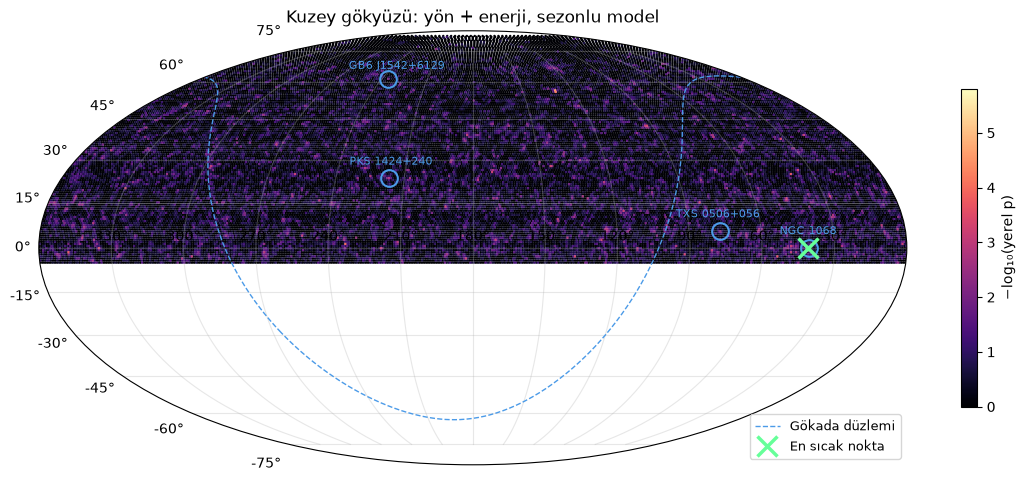

In [6]:
gx = lambda r: -(np.radians(r) - np.pi)
p_g = yerel_p(ts_g)
fig = plt.figure(figsize=(14, 7.5))
ax = fig.add_subplot(111, projection='mollweide')
renk = -np.log10(p_g); o = np.argsort(renk)
sc = ax.scatter(gx(ra_g[o]), np.radians(dec_g[o]), c=renk[o], s=3, cmap='magma',
                vmin=0, vmax=max(4, renk.max()), lw=0)
fig.colorbar(sc, ax=ax, shrink=0.55, label='−log₁₀(yerel p)')
gr, gd = ps.galaksi_duzlemi()
gxx, gyy = gx(gr), np.radians(gd)
kop = np.where(np.abs(np.diff(gxx)) > np.pi)[0] + 1
ax.plot(np.insert(gxx, kop, np.nan), np.insert(gyy, kop, np.nan), color='#4c9be8', lw=1, ls='--', label='Gökada düzlemi')
for ad, (rk, dk) in ps.KAYNAKLAR.items():
    ax.plot(gx(rk), np.radians(dk), 'o', mfc='none', mec='#4c9be8', ms=12, mew=1.5)
    ax.text(gx(rk), np.radians(dk) + 0.08, ad, color='#4c9be8', fontsize=8, ha='center')
en = np.argmax(ts_g)
ax.plot(gx(ra_g[en]), np.radians(dec_g[en]), 'x', color='#66ff99', ms=14, mew=2.5, label='En sıcak nokta')
ax.set_xticks(np.radians(np.arange(-150, 151, 30)))
ax.set_xticklabels([f'{(180 - t) % 360:.0f}°' for t in np.arange(-150, 151, 30)])
ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=9)
ax.set_title('Kuzey gökyüzü: yön + enerji, sezonlu model')
plt.savefig(RESULTS / 'asama13_gok_haritasi.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
r0, d0 = ra_g[en], dec_g[en]
# Karıştırılmış haritalara uygulananla AYNI ince tarama (±1°, 0.1° adım)
ns_i, g_i, ts_i, ra_i, dec_i = ps.ince_tara(T, r0, d0)
sicak = dict(ra=ra_i, dec=dec_i, ns=ns_i, gamma=g_i, TS=ts_i)
uzak = {ad: ps.acisal_uzaklik(sicak['ra'], sicak['dec'], rk, dk) for ad, (rk, dk) in ps.KAYNAKLAR.items()}
en_yakin = min(uzak, key=uzak.get)
# Hem gerçek hem karıştırılmış haritalarda: kaba ızgara + en sıcak noktada ince tarama (aynı işlem)
p_yerel = float(yerel_p(np.array([sicak['TS']]))[0])

N_eff = ps.etkin_deneme_sayisi(yerel_p(max_ts))
p_post_neff = 1 - (1 - p_yerel) ** N_eff
k_asan = int(np.sum(max_ts >= sicak['TS']))
p_post_mc = (k_asan + 1) / (len(max_ts) + 1)
# Doğrudan sayım modelden bağımsızdır; en az bir karıştırılmış harita gözleneni geçtiyse onu kullanırız.
# N_eff formülü "bağımsız noktalar" varsayımına dayanır; ince taramalı maksimumlarda bu varsayım
# zayıflar. Sadece hiçbir harita geçemediğinde (doğrudan sayım bir sınır verdiğinde) formüle başvururuz.
p_post = p_post_mc if k_asan > 0 else p_post_neff
a7 = pd.read_csv(RESULTS / 'asama11_post_trial.csv').iloc[0]

print(f"En sıcak nokta: RA {sicak['ra']:.2f}°, Dec {sicak['dec']:.2f}°  ({en_yakin}'a {uzak[en_yakin]:.2f}°)")
print(f"nₛ = {sicak['ns']:.1f}, γ = {sicak['gamma']:.1f}, TS (ince tarama) = {sicak['TS']:.1f}, TS (ızgara) = {ts_g.max():.1f}")
print(f"Yerel: {ps.sigma(p_yerel):.2f}σ")
print(f"Post-trial, doğrudan sayım: {k_asan}/{len(max_ts)} karıştırılmış harita daha sıcak → {ps.sigma(p_post_mc):.2f}σ")
print(f"Post-trial, N_eff formülü (N_eff ≈ {N_eff:,.0f}): {ps.sigma(p_post_neff):.2f}σ")
print(f"→ Raporlanan: {ps.sigma(p_post):.2f}σ")

karsilastirma = pd.DataFrame({
    'Aşama 7/11 (sadece yön)': ['40.97°, −0.10°', f"{ps.sigma(ps.yerel_p(np.load(RESULTS / 'asama7_harita.npz')['ts'].max())):.2f}σ", f"{a7['sigma_post']:.2f}σ"],
    'Aşama 13 (yön+enerji, sezonlu)': [f"{sicak['ra']:.2f}°, {sicak['dec']:.2f}°",
                                       f'{ps.sigma(p_yerel):.2f}σ', f'{ps.sigma(p_post):.2f}σ'],
    'IceCube 2020 (PRL)': ['40.9°, −0.3°', f'{ps.sigma(3.5e-7):.2f}σ', f'{ps.sigma(0.099):.2f}σ'],
}, index=['en sıcak nokta (RA, Dec)', 'yerel anlamlılık', 'post-trial anlamlılık'])
karsilastirma.to_csv(RESULTS / 'asama13_karsilastirma.csv')
pd.DataFrame([dict(**sicak, en_yakin=en_yakin, uzaklik=uzak[en_yakin], sigma_yerel=ps.sigma(p_yerel),
                   N_eff=N_eff, sigma_post=ps.sigma(p_post), sigma_post_dogrudan=ps.sigma(p_post_mc),
                   sigma_post_neff=ps.sigma(p_post_neff), k_asan=k_asan,
                   n_karisik=len(max_ts), eta=eta, sd=sd)]).to_csv(
    RESULTS / 'asama13_sicak_nokta.csv', index=False)
karsilastirma

En sıcak nokta: RA 40.87°, Dec -0.50°  (NGC 1068'a 0.53°)
nₛ = 58.7, γ = 4.5, TS (ince tarama) = 29.2, TS (ızgara) = 21.8
Yerel: 5.40σ
Post-trial, doğrudan sayım: 2/100 karıştırılmış harita daha sıcak → 1.89σ
Post-trial, N_eff formülü (N_eff ≈ 63,179): 2.86σ
→ Raporlanan: 1.89σ


,Aşama 7/11 (sadece yön),"Aşama 13 (yön+enerji, sezonlu)",IceCube 2020 (PRL)
"en sıcak nokta (RA, Dec)","40.97°, −0.10°","40.87°, -0.50°","40.9°, −0.3°"
yerel anlamlılık,4.37σ,5.40σ,4.96σ
post-trial anlamlılık,1.45σ,1.89σ,1.29σ


## Yorumlarken

- **Konum:** En sıcak noktanın yine NGC 1068'e ve IceCube'un bulduğu noktaya (40.9°, −0.3°) denk gelmesi bekleniyor.
- **Yerel anlamlılık artmalı:** enerji bilgisi sinyali arka plandan daha iyi ayırıyor.
- **Post-trial düşebilir:** γ'yı da serbest bıraktığımız için her noktada "daha çok şey denedik"; düzeltme büyüyor. IceCube'un post-trial değeri (p ≈ 0.1, ~1.3σ) de bu yüzden düşük. Bizim değerimizin onlarınkine yaklaşması, analizlerimizin aynı mantıkla çalıştığını gösterir.
- **Hâlâ fark varsa** sebepler: IceCube'un ızgarası çok daha ince (~0.1°, bizimki 0.7°: daha çok bilet → daha büyük düzeltme) ve ek kalite kesimleri.